# Shallow Velocity Model (Cross-Section Plots)

This notebook is used to plot cross sections for the shallow velocity model to improvement of LA basin for UCVM

### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import matplotlib.colors as mcolors
import matplotlib.tri as tri
import torch
import gpytorch
from pyproj import Proj, transform
from matplotlib import rcParams as rc
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from shapely.geometry import Polygon
import geopandas as gpd

#import user models
#from pylib_gp_twoscale import VelGPModel, Genevarikernel
from pylib_gp_twoscale import VelGPModel, Genevarikernel

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 16,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
norm = mcolors.Normalize(vmin=150., vmax=2000.)  
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

In [3]:
dir_out = '../Data/vel_data/'
df_ucvm = pd.read_csv(dir_out+'Cross_sections/1_vs_data_cross_section.txt', encoding='utf-8')

In [4]:
df_ucvm = df_ucvm[df_ucvm['lat'] == 33.6982]
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,vp,vs,dens,easting,northing,distance,Z_2.5,basin_idnum,predict_diff,predict_vs
1800,-117.8745,33.6982,0.000,10.161,227.716,cvms5,1594.77,878.867,2045.471,none,...,1594.77,878.867,2045.471,418956.121214,3.729037e+06,67243.462126,3080.0,1,-1.602725,176.957306
1801,-117.8745,33.6982,26.316,10.161,227.716,cvms5,1623.87,895.607,2053.921,none,...,1623.87,895.607,2053.921,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.792655,405.388722
1802,-117.8745,33.6982,52.632,10.161,227.716,cvms5,1652.97,912.348,2062.195,none,...,1652.97,912.348,2062.195,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.563870,519.128443
1803,-117.8745,33.6982,78.947,10.161,227.716,cvms5,1682.07,929.088,2070.295,none,...,1682.07,929.088,2070.295,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.441513,597.461572
1804,-117.8745,33.6982,105.263,10.161,227.716,cvms5,1711.17,945.829,2078.223,none,...,1711.17,945.829,2078.223,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.306399,696.217791
1805,-117.8745,33.6982,131.579,10.161,227.716,cvms5,1740.27,962.569,2085.982,none,...,1740.27,962.569,2085.982,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.222554,770.509476
1806,-117.8745,33.6982,157.895,10.161,227.716,cvms5,1769.37,979.309,2093.575,none,...,1769.37,979.309,2093.575,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.175379,821.776235
1807,-117.8745,33.6982,184.211,10.161,227.716,cvms5,1798.47,996.050,2101.003,none,...,1798.47,996.050,2101.003,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.126254,877.909360
1808,-117.8745,33.6982,210.526,10.161,227.716,cvms5,1827.57,1012.790,2108.271,none,...,1827.57,1012.790,2108.271,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.137225,882.923829
1809,-117.8745,33.6982,236.842,10.161,227.716,cvms5,1856.67,1029.531,2115.379,none,...,1856.67,1029.531,2115.379,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.118469,914.510782


In [5]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum','vs_value']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing', 'diff_smooth': 'diff'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_value
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,155.0
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,170.2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,196.5
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,191.9
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,202.0
...,...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1,354.0
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1,387.0
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1,445.0
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1,540.0


In [6]:
def get_vs0(vs30 = 228.2):
    p1 = -2.1688e-4
    p2 = 0.5182
    p3 = 69.452
    return p1 * vs30**2 + p2 * vs30 + p3

def get_k(vs30 = 228.2):
    r1 = -59.67
    r2 = -0.2722
    r3 = 11.132
    return np.exp(r1 * (vs30**r2) + r3)

def get_n(vs30 = 228.2):
    s1 = 4.110
    s2 = -1.0521e-4
    s3 = -10.827
    s4 = -7.6187e-3
    return s1 * np.exp(s2 * vs30) + s3 * np.exp(s4 * vs30)

def get_vs_z(z, vs30):
    z = np.asarray(z)
    vs0 = get_vs0(vs30)
    k = get_k(vs30)
    n = get_n(vs30)
    vs = np.where(
        z <= 2.5,
        vs0,
        vs0 * (1.0 + k * (z - 2.5))**(1.0 / n)
    )
    return vs

vs = get_vs_z(df_ucvm['vs_depth'], 228.2)
df_ucvm['shi'] = vs
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,vs,dens,easting,northing,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,shi
1800,-117.8745,33.6982,0.000,10.161,227.716,cvms5,1594.77,878.867,2045.471,none,...,878.867,2045.471,418956.121214,3.729037e+06,67243.462126,3080.0,1,-1.602725,176.957306,176.411162
1801,-117.8745,33.6982,26.316,10.161,227.716,cvms5,1623.87,895.607,2053.921,none,...,895.607,2053.921,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.792655,405.388722,296.997864
1802,-117.8745,33.6982,52.632,10.161,227.716,cvms5,1652.97,912.348,2062.195,none,...,912.348,2062.195,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.563870,519.128443,385.833332
1803,-117.8745,33.6982,78.947,10.161,227.716,cvms5,1682.07,929.088,2070.295,none,...,929.088,2070.295,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.441513,597.461572,456.246353
1804,-117.8745,33.6982,105.263,10.161,227.716,cvms5,1711.17,945.829,2078.223,none,...,945.829,2078.223,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.306399,696.217791,516.268163
1805,-117.8745,33.6982,131.579,10.161,227.716,cvms5,1740.27,962.569,2085.982,none,...,962.569,2085.982,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.222554,770.509476,569.392313
1806,-117.8745,33.6982,157.895,10.161,227.716,cvms5,1769.37,979.309,2093.575,none,...,979.309,2093.575,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.175379,821.776235,617.513688
1807,-117.8745,33.6982,184.211,10.161,227.716,cvms5,1798.47,996.050,2101.003,none,...,996.050,2101.003,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.126254,877.909360,661.794880
1808,-117.8745,33.6982,210.526,10.161,227.716,cvms5,1827.57,1012.790,2108.271,none,...,1012.790,2108.271,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.137225,882.923829,703.008015
1809,-117.8745,33.6982,236.842,10.161,227.716,cvms5,1856.67,1029.531,2115.379,none,...,1029.531,2115.379,418956.121214,3.729037e+06,67243.462126,3080.0,1,-0.118469,914.510782,741.701568


In [7]:
from pyproj import Transformer

target_lat = 33.6982
target_lon = -117.8745

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32611", always_xy=True)
target_easting, target_northing = transformer.transform(target_lon, target_lat)

dist = np.sqrt(
    (df_measure["easting"].to_numpy() - target_easting)**2 +
    (df_measure["northing"].to_numpy() - target_northing)**2
)

df_measure["dist_m"] = dist

row_nearest = df_measure.loc[df_measure["dist_m"].idxmin()]
row_nearest

vs_depth                2.500000e-01
Z_2.5                   3.440000e+03
surf_elevation          9.592000e+00
easting                 4.184478e+05
northing                3.729208e+06
diff                   -2.436663e+00
velocity_metadata_id    2.445000e+03
vs30                    2.162150e+02
basin_idnum             1.000000e+00
vs_value                7.700000e+01
dist_m                  5.361878e+02
Name: 10697, dtype: float64

In [8]:
df_close = df_measure[df_measure['velocity_metadata_id'] == 2445]
df_close

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_value,dist_m
10697,0.25,3440.0,9.592,418447.81319,3.729208e+06,-2.436663,2445,216.215,1,77.0,536.18783
10698,0.90,3440.0,9.592,418447.81319,3.729208e+06,-2.259131,2445,216.215,1,92.0,536.18783
10699,1.85,3440.0,9.592,418447.81319,3.729208e+06,-2.010893,2445,216.215,1,118.0,536.18783
10700,3.25,3440.0,9.592,418447.81319,3.729208e+06,-1.922734,2445,216.215,1,129.0,536.18783
10701,5.35,3440.0,9.592,418447.81319,3.729208e+06,-1.807266,2445,216.215,1,145.0,536.18783
10702,8.50,3440.0,9.592,418447.81319,3.729208e+06,-1.348095,2445,216.215,1,230.0,536.18783
10703,13.25,3440.0,9.592,418447.81319,3.729208e+06,-1.248181,2445,216.215,1,255.0,536.18783
10704,20.35,3440.0,9.592,418447.81319,3.729208e+06,-1.117560,2445,216.215,1,292.0,536.18783
10705,31.00,3440.0,9.592,418447.81319,3.729208e+06,-0.969690,2445,216.215,1,341.0,536.18783
10706,44.45,3440.0,9.592,418447.81319,3.729208e+06,-0.860022,2445,216.215,1,384.0,536.18783


findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

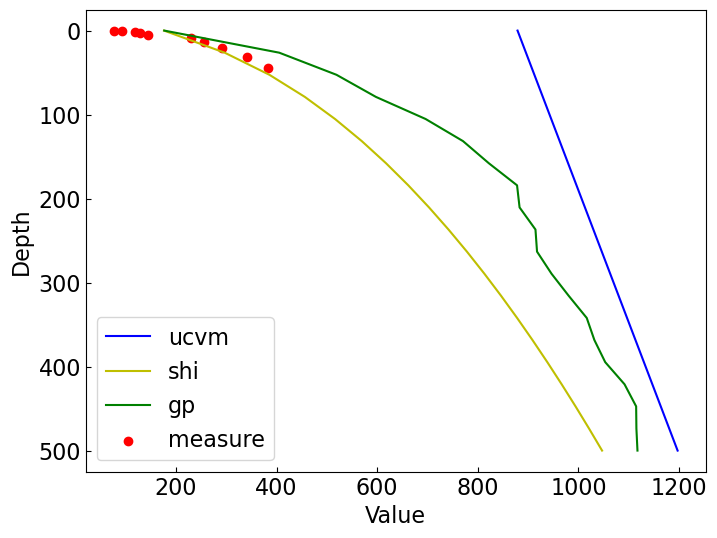

In [9]:
plt.figure(figsize=(8, 6))
plt.plot(df_ucvm['cvm_vs'], df_ucvm['vs_depth'], color='b', label="ucvm")
plt.plot(df_ucvm['shi'], df_ucvm['vs_depth'], color='y', label="shi")
plt.plot(df_ucvm['predict_vs'], df_ucvm['vs_depth'], color='g', label="gp")
plt.scatter(df_close['vs_value'], df_close['vs_depth'], color='r', label="measure")
plt.gca().invert_yaxis()
plt.xlabel("Value")
plt.ylabel("Depth")
plt.legend()
plt.grid()
plt.show()